# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [6]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"

# TODO: carga el archivo en un DataFrame llamado df
df = pd.read_csv(DATA_PATH)


In [8]:
# TODO: reporta forma, tipos, nulos, duplicados y distribución de target
print("--- Forma ---")
print(df.shape)

print("\n--- Tipos ---")
print(df.dtypes)

print("\n--- Nulos ---")
print(df.isnull().sum())

print("\n--- Duplicados ---")
print(df.duplicated().sum())

print("\n--- Distribución de target ---")
print(df['target'].value_counts())


--- Forma ---
(178, 14)

--- Tipos ---
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object

--- Nulos ---
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             

**Conclusión de calidad:**

> Describe brevemente qué encontraste y qué decisión tomaste.

## 2. Split train/test

In [10]:
# TODO: crea train_df (80 %) y test_df (20 %)
# Requisitos: stratify=df["target"] y random_state=RANDOM_STATE
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["target"],
    random_state=RANDOM_STATE
)


In [11]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

/tmp/ipykernel_4976/889572162.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train_df, x='target', palette='viridis')


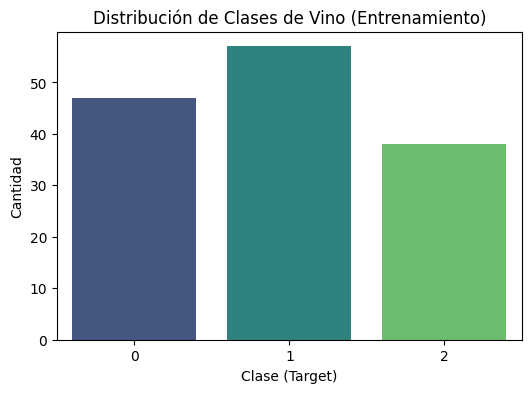

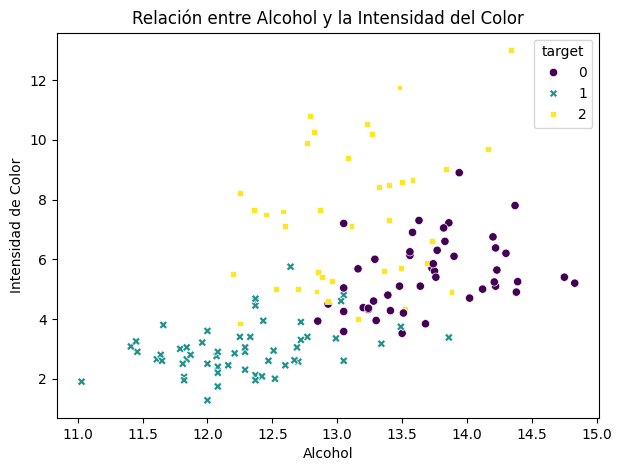

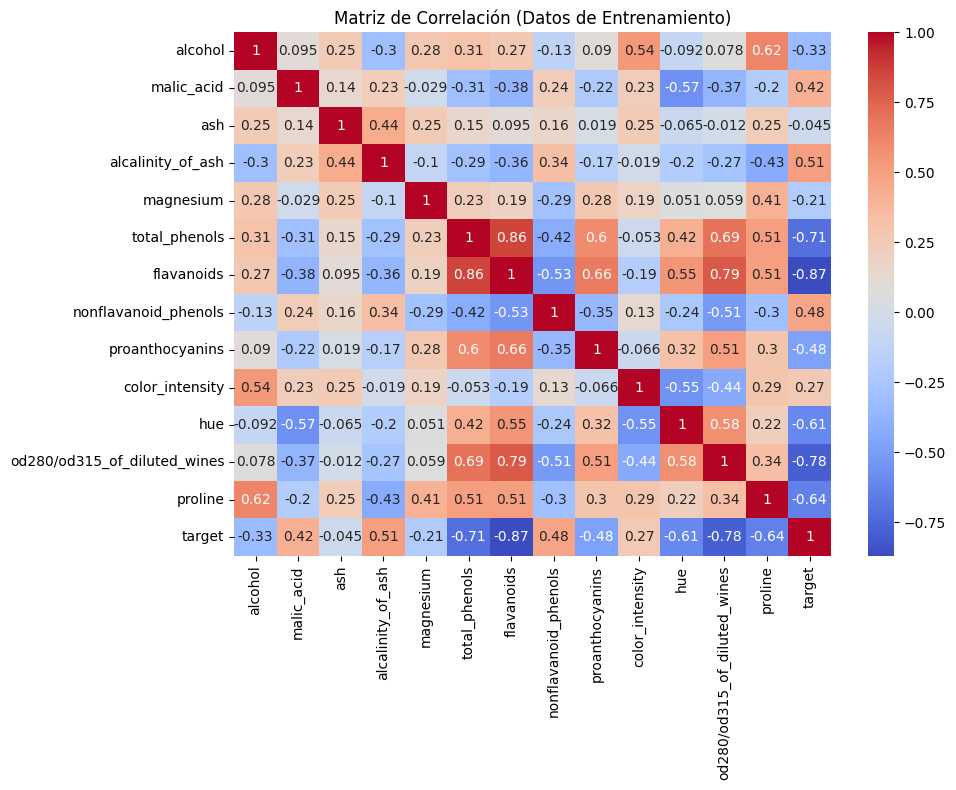

In [12]:
# TODO: crea al menos tres visualizaciones usando solamente train_df

# 1. Distribución de la variable target
plt.figure(figsize=(6, 4))
sns.countplot(data=train_df, x='target', palette='viridis')
plt.title('Distribución de Clases de Vino (Entrenamiento)')
plt.xlabel('Clase (Target)')
plt.ylabel('Cantidad')
plt.show()

# 2. Relación entre Alcohol y Color Intensity por Clase
plt.figure(figsize=(7, 5))
sns.scatterplot(data=train_df, x='alcohol', y='color_intensity', hue='target', palette='viridis', style='target')
plt.title('Relación entre Alcohol y la Intensidad del Color')
plt.xlabel('Alcohol')
plt.ylabel('Intensidad de Color')
plt.show()

# 3. Matriz de correlación de características seleccionadas
plt.figure(figsize=(10, 8))
corr_matrix = train_df.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2g", cmap='coolwarm', cbar=True)
plt.title('Matriz de Correlación (Datos de Entrenamiento)')
plt.tight_layout()
plt.show()


**Hallazgos:**

1.
2.
3.

## 4. Persistencia de datos y contrato

In [14]:
# TODO: reinicia los índices y guarda train.csv y test.csv sin el índice
train_df_clean = train_df.reset_index(drop=True)
test_df_clean = test_df.reset_index(drop=True)

train_df_clean.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df_clean.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

# TODO: crea data_contract.json con target, features, random_state y test_size
features = [col for col in df.columns if col != "target"]

contract = {
    "target": "target",
    "features": features,
    "random_state": RANDOM_STATE,
    "test_size": 0.2
}

with open(ARTIFACTS_DIR / "data_contract.json", "w") as f:
    json.dump(contract, f, indent=4)


In [15]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [ ] Cargué el CSV desde `data/raw`.
- [ ] Revisé calidad y distribución de la clase.
- [ ] Realicé un split estratificado.
- [ ] No exploré el conjunto de test.
- [ ] Guardé los tres artefactos requeridos.